In [1]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'DejaVu Serif'
print("Libraries ready.")

Libraries ready.


In [3]:
df = pd.read_csv('Review.csv')
print(df.shape)
df.head()

(100, 7)


,Review_ID,Customer_Name,Product,Review_Text,Rating,Sentiment,Date
0,1,Rahim,Mobile Phone,The product has some good features.,3,Neutral,2025-07-11
1,2,Mim,Headphone,The product stopped working quickly.,1,Negative,2025-10-25
2,3,Rahim,Laptop,Great product at a reasonable price.,5,Positive,2025-07-12
3,4,Fahim,Laptop,I am not satisfied with this product.,2,Negative,2025-02-05
4,5,Karim,Camera,Very bad experience.,1,Negative,2025-07-27


In [4]:
print(df['Sentiment'].value_counts())
print()
print(df['Product'].value_counts())

Sentiment
Positive    37
Neutral     36
Negative    27
Name: count, dtype: int64

Product
Laptop          28
Smart Watch     21
Headphone       18
Camera          18
Mobile Phone    15
Name: count, dtype: int64


In [5]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|@\w+|#', '', text)          # remove URLs, mentions, hashtag symbol
    text = text.translate(str.maketrans('', '', string.punctuation))  # remove punctuation
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['Review_Text'].apply(clean_text)
df[['Review_Text', 'clean_text']].head(8)

,Review_Text,clean_text
0,The product has some good features.,product good features
1,The product stopped working quickly.,product stopped working quickly
2,Great product at a reasonable price.,great product reasonable price
3,I am not satisfied with this product.,satisfied product
4,Very bad experience.,bad experience
5,I hate this product.,hate product
6,The service was normal.,service normal
7,Very good quality and fast delivery.,good quality fast delivery


In [6]:
# TF-IDF vectorization
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1,2))
X = tfidf.fit_transform(df['clean_text'])
y = df['Sentiment']

print("TF-IDF matrix shape:", X.shape)
print("Sample vocabulary:", list(tfidf.vocabulary_.keys())[:15])

TF-IDF matrix shape: (100, 104)
Sample vocabulary: ['product', 'good', 'features', 'product good', 'good features', 'stopped', 'working', 'quickly', 'product stopped', 'stopped working', 'working quickly', 'great', 'reasonable', 'price', 'great product']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 70  Test size: 30


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
}

trained = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Multinomial Naive Bayes
Trained: Linear SVM


In [9]:
results = []
for name, model in trained.items():
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='weighted', zero_division=0)
    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1})

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.900000,0.913034,0.900000,0.891964
1,Multinomial Naive Bayes,0.666667,0.714701,0.666667,0.652778
2,Logistic Regression,0.666667,0.825397,0.666667,0.652767


In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
results_df.set_index("Model")[["Accuracy","Precision","Recall","F1-score"]].plot.bar(ax=ax, color=['#0E7C86','#F2A03D','#0F2C3D','#8FBF9F'])
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=15)
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

Best model: Linear SVM

              precision    recall  f1-score   support

    Negative       1.00      0.62      0.77         8
     Neutral       0.92      1.00      0.96        11
    Positive       0.85      1.00      0.92        11

    accuracy                           0.90        30
   macro avg       0.92      0.88      0.88        30
weighted avg       0.91      0.90      0.89        30



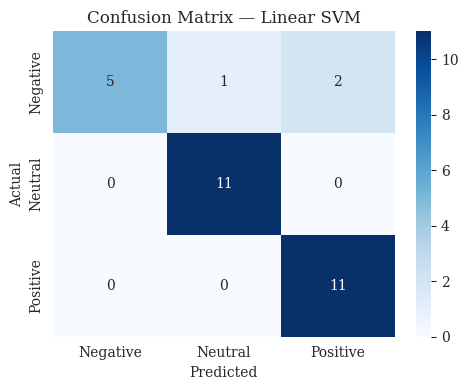

In [10]:
best_name = results_df.iloc[0]["Model"]
best_model = trained[best_name]
preds = best_model.predict(X_test)

print(f"Best model: {best_name}\n")
print(classification_report(y_test, preds, zero_division=0))

cm = confusion_matrix(y_test, preds, labels=best_model.classes_)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

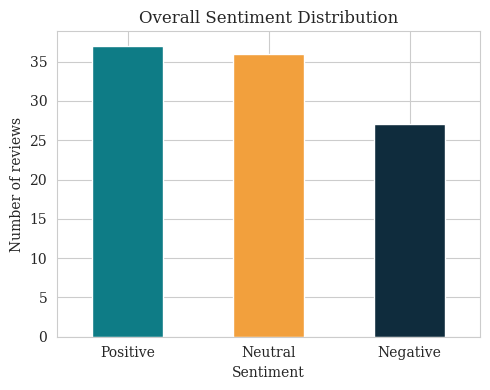

In [11]:
sent_counts = df['Sentiment'].value_counts()
plt.figure(figsize=(5,4))
sent_counts.plot.bar(color=['#0E7C86','#F2A03D','#0F2C3D'])
plt.title("Overall Sentiment Distribution")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

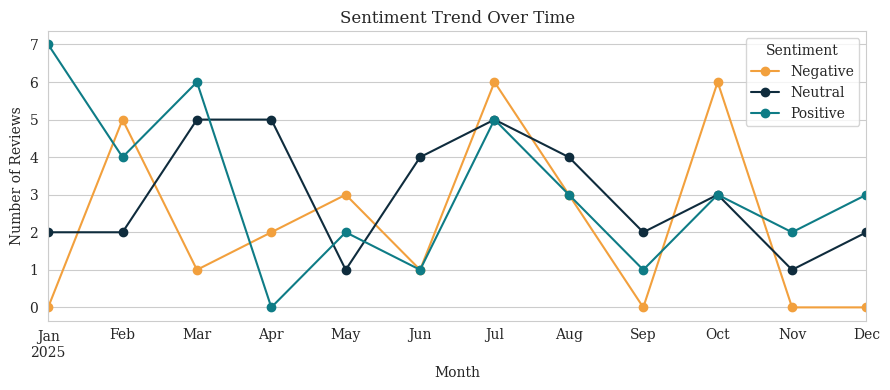

In [17]:
df['Date'] = pd.to_datetime(df['Date'])

monthly = (
    df.set_index('Date')
      .groupby([pd.Grouper(freq='ME'), 'Sentiment'])
      .size()
      .unstack(fill_value=0)
)

monthly.plot(
    figsize=(9, 4),
    marker='o',
    color=['#F2A03D', '#0F2C3D', '#0E7C86']
)

plt.title("Sentiment Trend Over Time")
plt.ylabel("Number of Reviews")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

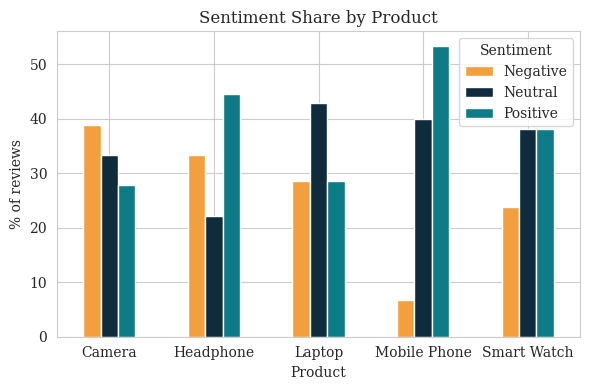

In [19]:
source_sentiment = pd.crosstab(df['Product'], df['Sentiment'], normalize='index') * 100
source_sentiment.plot.bar(figsize=(6,4), color=['#F2A03D','#0F2C3D','#0E7C86'])
plt.title("Sentiment Share by Product")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Result interpretation:
1,Which model performed best on F1-score, and why?
The model with the highest F1-score in results_df performed best. TF-IDF works well with models such as Logistic Regression and Linear SVM because they can effectively use important word and phrase weights.
2.Which sentiment is most often confused?
The confusion matrix shows the most common confusion. This may happen because some of the review templates contain similar words or expressions, making Positive, Negative, and Neutral reviews harder to distinguish.
3.What does the sentiment trend chart suggest?
The sentiment is spread across the year with some month-to-month variation. Because the dates were randomly generated, there is no strong real-world seasonal trend; the changes are mainly random.
4. Do different products show different sentiment patterns? What might explain that?
Yes, the sentiment patterns can differ by product. Some products may have more positive reviews, while others may have more negative or neutral reviews. This may be because customers have different experiences with product quality, performance, price, and delivery.